# Part C: preprocessing comparison

Shows the original image and the four preprocessing modes in `src/preprocess.py` for several image types found in APTOS:
normal, severe DR, truncated field of view, underexposed and overexposed.

Examples are picked automatically from the **training split only** (from `splits.csv`), so no validation or test image is used here.
The figure is saved to `results/figures/preprocessing_comparison.png` for the slides and reports.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocess import MODES, crop_black_border, fov_mask, load_rgb, preprocess

IMG_DIR = ROOT / "data/raw/Aptos2019 retinal image database/train_images"
FIG_DIR = ROOT / "results/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

splits = pd.read_csv(ROOT / "splits.csv")
train = splits[splits.split == "train"].reset_index(drop=True)
train.shape

(2563, 6)

## Image statistics on a training sample

For a random sample of training images (fixed seed), measure:
- `aspect`: width / height after cropping the black border (> 1 means the top and bottom of the fundus are cut off)
- `brightness`: mean grey level inside the field of view

In [2]:
def image_stats(id_code):
    img = load_rgb(IMG_DIR / f"{id_code}.png")
    small = cv2.resize(img, (512, int(512 * img.shape[0] / img.shape[1])), interpolation=cv2.INTER_AREA)
    crop = crop_black_border(small)
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
    return crop.shape[1] / crop.shape[0], gray[fov_mask(small)].mean()

sample = train.sample(400, random_state=9027).reset_index(drop=True)
sample[["aspect", "brightness"]] = [image_stats(i) for i in sample.id_code]
sample[["aspect", "brightness"]].describe().round(2)

,aspect,brightness
count,400.00,400.00
mean,1.17,86.85
std,0.14,21.62
min,0.96,33.64
25%,1.00,72.15
50%,1.25,90.54
75%,1.31,103.16
max,1.33,154.91


## Pick one example of each type

In [3]:
full = sample[sample.aspect < 1.05]
mid = sample.brightness.median()

def closest_to_median(df):
    return df.iloc[(df.brightness - mid).abs().argsort().iloc[0]]

examples = {
    "Normal": closest_to_median(full[full.diagnosis == 0]),
    "Severe DR": closest_to_median(full[full.diagnosis >= 3]),
    "Truncated field": sample.loc[sample.aspect.idxmax()],
    "Underexposed": sample.loc[sample.brightness.idxmin()],
    "Overexposed": sample.loc[sample.brightness.idxmax()],
}
pd.DataFrame(examples).T[["id_code", "diagnosis", "aspect", "brightness"]]

,id_code,diagnosis,aspect,brightness
Normal,898f0bc8acfa,0,1.0,90.466748
Severe DR,6c3745a222da,4,1.0,56.73912
Truncated field,9b95d6203406,2,1.333333,78.870798
Underexposed,6f4719c6bb4b,4,1.322997,33.636021
Overexposed,6a244e855d0e,3,1.282353,154.905179


## Comparison figure

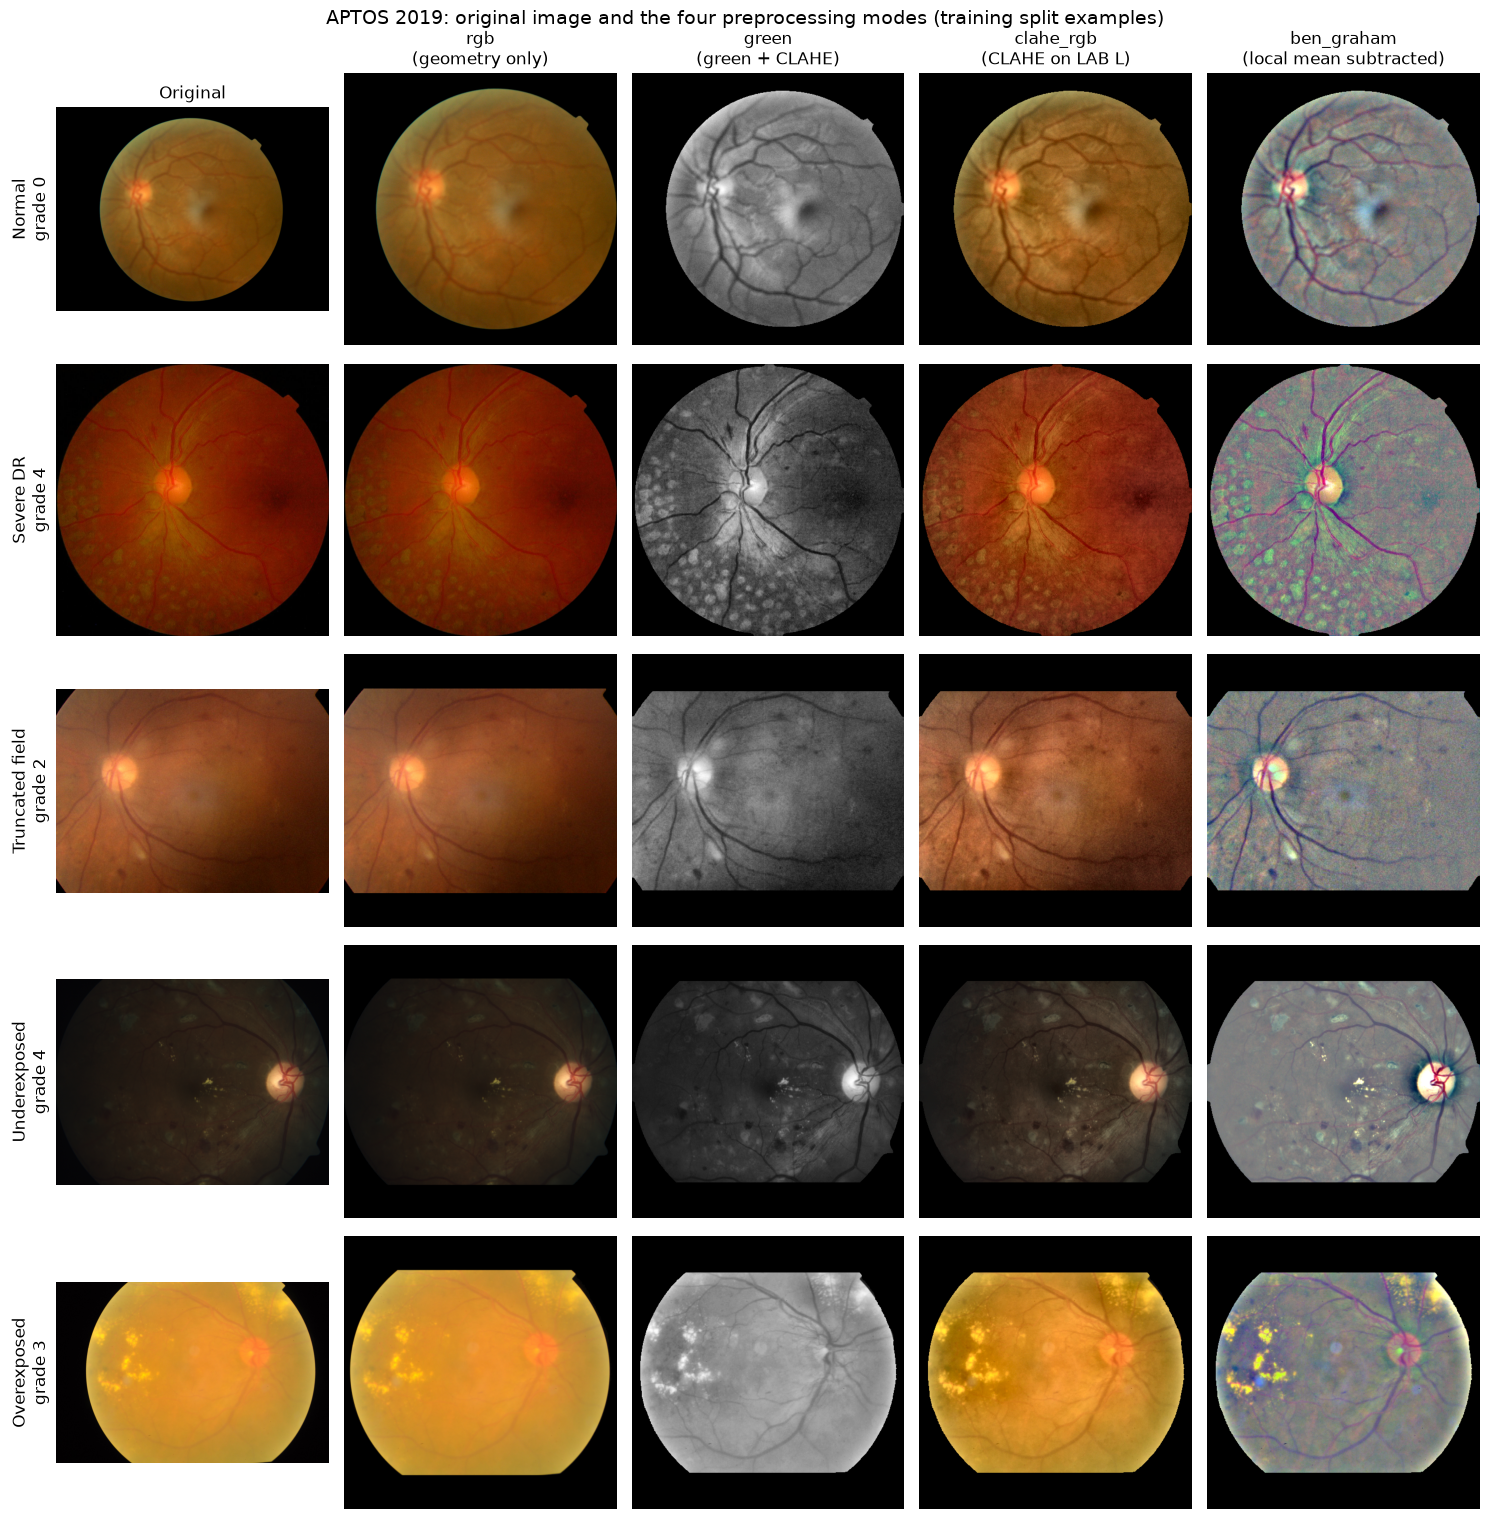

In [4]:
SIZE = 512
titles = ["Original", "rgb\n(geometry only)", "green\n(green + CLAHE)", "clahe_rgb\n(CLAHE on LAB L)", "ben_graham\n(local mean subtracted)"]

fig, axes = plt.subplots(len(examples), 5, figsize=(15, 3.1 * len(examples)))
for r, (label, row) in enumerate(examples.items()):
    img = load_rgb(IMG_DIR / f"{row.id_code}.png")
    panels = [img] + [preprocess(img, SIZE, m) for m in MODES]
    for c, p in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(p, cmap="gray" if p.ndim == 2 else None)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        if r == 0:
            ax.set_title(titles[c], fontsize=12)
    axes[r, 0].set_ylabel(f"{label}\ngrade {row.diagnosis}", fontsize=12)

fig.suptitle("APTOS 2019: original image and the four preprocessing modes (training split examples)", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "preprocessing_comparison.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## What to look for

- **Truncated field**: the border crop and field-of-view mask follow the real edge, so no black bars or bright halo appear inside the image.
- **Underexposed / overexposed**: CLAHE (`green`, `clahe_rgb`) evens out contrast; `ben_graham` removes most of the illumination difference between images.
- **Severe DR**: lesions (exudates, haemorrhages) are easier to see in `green` and `ben_graham`, which is why `green` is used for the classical pipeline (A).
- `clahe_rgb` keeps natural colour, which suits ImageNet-pretrained CNNs (B).